In [36]:
# EarlyStopping 클래스 구현

import math

class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.0):
        if (isinstance(patience, bool) or not isinstance(patience, int) or patience < 1):
            raise ValueError("patience는 1 이상의 정수여야 합니다.")

        min_delta = float(min_delta)
        if not math.isfinite(min_delta) or min_delta < 0:
            raise ValueError("min_delta는 0 이상의 유한한 값이어야 합니다.")

        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = None
        self.counter = 0
        self.should_stop = False

    def step(self, val_loss):
        val_loss = float(val_loss)
        if not math.isfinite(val_loss):
            raise ValueError("val_loss가 Nan 또는 inf입니다. 학습과 데이터를 점검하세요.")

        if self.should_stop:
            return True, False
        if self.best_loss is None:
            self.best_loss = val_loss
            self.counter = 0
            return False, True

        improvement = self.best_loss - val_loss

        improved = (improvement > 0.0 and improvement >= self.min_delta)

        if improved:
            self.best_loss = val_loss
            self.counter =0
        else:
            self.counter += 1

        self.should_stop = self.counter >= self.patience
        return self.should_stop, improved

    def state_dict(self):
        return {
            "patience": self.patience,
            "min_delta": self.min_delta,
            "best_loss": self.best_loss,
            "counter": self.counter,
            "should_stop": self.should_stop
        }

    def load_state_dict(self, state):
        required_keys = {
            "patience",
            "min_delta",
            "best_loss",
            "counter",
            "should_stop",
        }
        missing_keys = required_keys - state.keys()
        if missing_keys:
            raise KeyError(f"EarlyStopping 상태 key가 없습니다: {sorted(missing_keys)}")

        patience = int(state["patience"])
        min_delta = float(state["min_delta"])
        best_loss = state["best_loss"]
        counter = int(state["counter"])

        if patience < 1:
            raise ValueError("복원한 patience가 1보다 작습니다.")
        if not math.isfinite(min_delta) or min_delta < 0:
            raise ValueError('복원한 min_delta가 올바르지 않습니다.')
        if best_loss is not None:
            best_loss = float(best_loss)
            if not math.isfinite(best_loss):
                raise ValueError("복원한 best_loss가 유한하지 않습니다")
        if counter < 0:
            raise ValueError("복원한 counter가 음수입니다.")

        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = best_loss
        self.counter = counter
        self.should_stop = bool(state["should_stop"])


In [37]:
# 상태 저장과 복원을 확인

early_stopper = EarlyStopping(patience=3, min_delta=0.001)
shoud_stop, improved = early_stopper.step(0.50)
saved_state = early_stopper.state_dict()

restored_stopper = EarlyStopping()
restored_stopper.load_state_dict(saved_state)

print(f"improved: {improved}")
print(f"restored best_loss: {restored_stopper.best_loss}")
print(f"restored counter: {restored_stopper.counter}")

improved: True
restored best_loss: 0.5
restored counter: 0


In [38]:
# 데이터와 학습 객체

import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from pathlib import Path

# ========== SEED 고정
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# ========== 가상 분류 데이터 생성
num_samples = 1200
input_dim = 20
num_classes = 3

data_generator = torch.Generator().manual_seed(SEED)
X = torch.randn(num_samples, input_dim, generator=data_generator)
true_weight = torch.randn(input_dim, num_classes, generator=data_generator)
true_bias = torch.randn(num_classes, generator=data_generator)
scores = X @ true_weight + true_bias
scores += 0.5 * torch.randn(scores.shape, generator=data_generator)
y = scores.argmax(dim=1) # 가장 큰 값이 있는 위치(인덱스)

dataset = TensorDataset(X, y)
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

# ========== train / validation/test 분리 (088/200/200)
split_generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset, test_dataset = random_split(dataset, [800, 200, 200], generator=split_generator)
print(f"train: {len(train_dataset)}")
print(f"validation: {len(val_dataset)}")
print(f"test: {len(test_dataset)}")

# ========== DataLoader 생성
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# ========== MLP 모델 생성
class EarlyStoppingDemoMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

model = EarlyStoppingDemoMLP(input_dim=input_dim, num_classes=num_classes).to(device)

# ========== Loss와 optimizer 정의
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# ========== history와 config
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "improved": [],
    "early_stop_counter": [],
}

config = {
    "seed": SEED,
    "input_dim": input_dim,
    "num_classes": num_classes,
    "batch_size": 64,
    "learning_rate": 0.001,
}

run_dir = Path(r"C:\Users\limux\Documents\1. Projects\KANT Private LLM Infra Engineer\kant-llm-engineer-main\step1_llm-foundations\ch03_deep-learning-basic\early_stopping_demo")
run_dir.mkdir(parents=True, exist_ok=True)

# ========== 1 epoch 학습 함수
def train_one_epoch(model, train_loader, loss_fn, optimizer, device):
    model.train()
    epoch_loss = 0.0
    epoch_samples = 0
    epoch_correct = 0
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * X_batch.size(0)
        epoch_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        epoch_samples += X_batch.size(0)

    avg_loss = epoch_loss / epoch_samples
    avg_acc = epoch_correct / epoch_samples
    return avg_loss, avg_acc


# ========== validation / test 함수
@torch.no_grad()
def evaluate(model, data_loader, loss_fn, device):
    model.eval()
    epoch_loss = 0.0
    epoch_samples = 0
    epoch_correct = 0
    for X_batch, y_batch in data_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)

        epoch_loss += loss.item() * X_batch.size(0)
        epoch_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        epoch_samples += X_batch.size(0)

    avg_loss = epoch_loss / epoch_samples
    avg_acc = epoch_correct / epoch_samples
    return avg_loss, avg_acc

# ========== checkpoint 저장 함수
def save_checkpoint(model, optimizer, completed_epochs, best_val_loss, history, config, loader_generator, path, early_stopper):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "completed_epochs": completed_epochs,
        "best_val_loss": best_val_loss,
        "history": history,
        "config": config,
        "loader_generator_state": loader_generator.get_state(),
        "ealry_stopper_state": early_stopper.state_dict(),
        "torch_rng_state": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        checkpoint["cuda_rng_state_all"] = torch.cuda.get_rng_state_all()

    temporary_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(path)

X shape: torch.Size([1200, 20])
y shape: torch.Size([1200])
train: 800
validation: 200
test: 200


In [39]:
# 학습 루프에 EarlyStopping 연결
def fit_with_early_stopping(
        model, train_loader, val_loader, test_loader, loss_fn, optimizer, device,
        num_epochs, history, config, loader_generator, run_dir,
        train_one_epoch_fn, evaluate_fn, save_checkpoint_fn,
        patience=3, min_delta=0.001,
):
    early_stopper = EarlyStopping(patience=patience, min_delta=min_delta)
    run_dir = Path(run_dir)
    checkpoint_dir = run_dir / "checkpoints"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    best_model_path = checkpoint_dir / "best_weights.pt"
    last_checkpoint_path = checkpoint_dir / "last.pt"
    history.setdefault("improved", [])
    history.setdefault("early_stop_counter", [])
    history["early_stopping_patience"] = patience
    history["early_stopping_min_delta"] = min_delta

    for epoch in range(1, num_epochs + 1):
        train_loss, train_acc = train_one_epoch_fn(model, train_loader, loss_fn, optimizer, device)
        val_loss, val_acc = evaluate_fn(model, val_loader, loss_fn, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        should_stop, improved = early_stopper.step(val_loss)
        history["improved"].append(improved)
        history["early_stop_counter"].append(early_stopper.counter)

        if improved:
            temporary_path = best_model_path.with_suffix(best_model_path.suffix + ".tmp")
            torch.save(model.state_dict(), temporary_path)
            temporary_path.replace(best_model_path)
            print(f" -> best model saved: {best_model_path}")

        save_checkpoint_fn(
            model = model,
            optimizer = optimizer,
            completed_epochs = epoch,
            best_val_loss = early_stopper.best_loss,
            history = history,
            config = config,
            loader_generator = loader_generator,
            path = last_checkpoint_path,
            early_stopper = early_stopper,
        )

        print(
            f"Epoch {epoch:03d}/{num_epochs:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"train_acc={train_acc:.4f} | "
            f"valid_loss={val_loss:.4f} | "
            f"valid_acc={val_acc:.4f}"
        )

        if should_stop:
            print(f"Early stopping triggered at epoch {epoch}")
            break

    best_state = torch.load(
        best_model_path,
        map_location = "cpu",
        weights_only = True,
    )
    model.load_state_dict(best_state)
    model.eval()
    test_loss, test_acc = evaluate_fn(model, test_loader, loss_fn, device)
    print(f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}")

    return model, history, test_loss, test_acc


In [40]:
model, history, test_loss, test_acc = fit_with_early_stopping(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    device=device,
    num_epochs=50,
    history=history,
    config=config,
    loader_generator=loader_generator,
    run_dir=run_dir,
    train_one_epoch_fn=train_one_epoch,
    evaluate_fn=evaluate,
    save_checkpoint_fn=save_checkpoint,
    patience=3,
    min_delta=0.02
)

 -> best model saved: C:\Users\limux\Documents\1. Projects\KANT Private LLM Infra Engineer\kant-llm-engineer-main\step1_llm-foundations\ch03_deep-learning-basic\early_stopping_demo\checkpoints\best_weights.pt
Epoch 001/050 | train_loss=1.1148 | train_acc=0.3937 | valid_loss=1.0433 | valid_acc=0.4750
 -> best model saved: C:\Users\limux\Documents\1. Projects\KANT Private LLM Infra Engineer\kant-llm-engineer-main\step1_llm-foundations\ch03_deep-learning-basic\early_stopping_demo\checkpoints\best_weights.pt
Epoch 002/050 | train_loss=1.0164 | train_acc=0.4713 | valid_loss=0.9496 | valid_acc=0.6400
 -> best model saved: C:\Users\limux\Documents\1. Projects\KANT Private LLM Infra Engineer\kant-llm-engineer-main\step1_llm-foundations\ch03_deep-learning-basic\early_stopping_demo\checkpoints\best_weights.pt
Epoch 003/050 | train_loss=0.9162 | train_acc=0.6075 | valid_loss=0.8638 | valid_acc=0.7300
 -> best model saved: C:\Users\limux\Documents\1. Projects\KANT Private LLM Infra Engineer\kant-l

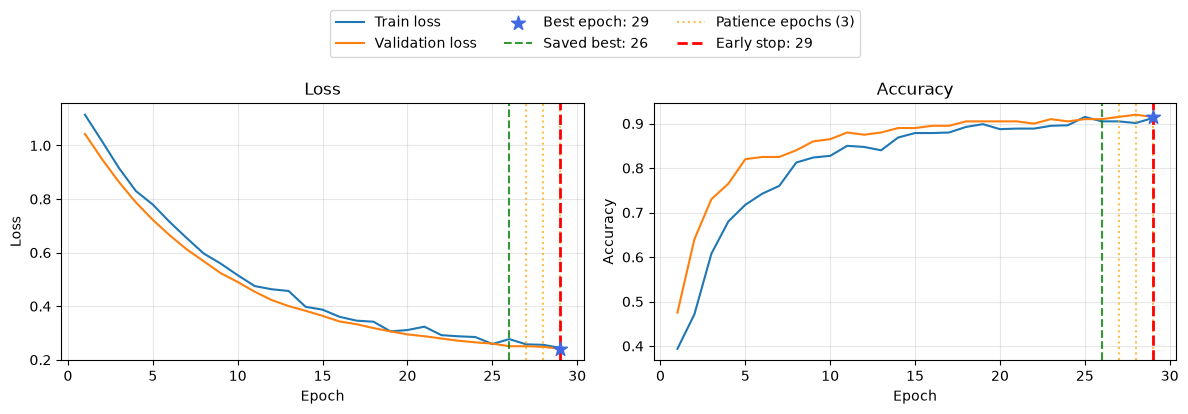

In [41]:
# 학습 곡선과 Early Stopping 지점 시각화
import matplotlib.pyplot as plt

epochs = list(range(1, len(history["val_loss"]) + 1))
patience = history["early_stopping_patience"]
counter_history = history["early_stop_counter"]

best_epoch = min(epochs, key=lambda epoch: history["val_loss"][epoch - 1])
saved_best_epoch = max(
    epoch for epoch, improved in zip(epochs, history["improved"]) if improved
)
patience_epochs = [
    epoch
    for epoch, counter in zip(epochs, counter_history)
    if epoch > saved_best_epoch and counter > 0
]
stop_epoch = next(
    (epoch for epoch, counter in zip(epochs, counter_history) if counter >= patience),
    None,
)

figure, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="Train loss")
axes[0].plot(epochs, history["val_loss"], label="Validation loss")
axes[0].scatter(
    best_epoch, history["val_loss"][best_epoch - 1],
    color="royalblue", marker="*", s=110, zorder=5,
    label=f"Best epoch: {best_epoch}",
)
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Loss")

axes[1].plot(epochs, history["train_acc"], label="Train accuracy")
axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
axes[1].scatter(
    best_epoch, history["val_acc"][best_epoch - 1],
    color="royalblue", marker="*", s=110, zorder=5,
)
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")

for axis in axes:
    axis.axvline(
        saved_best_epoch, color="green", linestyle="--", alpha=0.8,
        label=f"Saved best: {saved_best_epoch}",
    )
    for index, epoch in enumerate(patience_epochs):
        axis.axvline(
            epoch, color="orange", linestyle=":", alpha=0.7,
            label=f"Patience epochs ({patience})" if index == 0 else None,
        )
    if stop_epoch is not None:
        axis.axvline(
            stop_epoch, color="red", linestyle="--", linewidth=2,
            label=f"Early stop: {stop_epoch}",
        )
    axis.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.04), ncol=3)
figure.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()